# EDA: Manga vs. Light-Novel Anime Adaptation Ratings

*Ruby Ho - SEIS 631: Choose Your Own Hypothesis*

**Research focus:** Among finished TV anime released from 2015 to 2025, do anime adapted from manga and anime adapted from light novels differ in their AniList user ratings?

This notebook follows the same EDA structure as my earlier class assignment: provenance and scope, structure and quality, distributions, relationships, readiness, and dataset-specific questions.

## Setup and loading

This project keeps both the raw API extract and the analysis-ready file. The raw file preserves the records returned by AniList; the analysis file removes only records with no `average_score`, because those records cannot contribute to a rating comparison.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from pathlib import Path

In [2]:
raw = pd.read_csv("anilist_raw_manga_vs_light_novel_2015_2025.csv")
anime = pd.read_csv("anilist_analysis_manga_vs_light_novel_2015_2025.csv")

In [3]:
raw_shape = pd.DataFrame({
    "Dataset": ["Raw API extract"],
    "Number of Rows": [raw.shape[0]],
    "Number of Columns": [raw.shape[1]]
})

display(raw_shape)

,Dataset,Number of Rows,Number of Columns
0,Raw API extract,1147,25


The raw AniList extract contains 1,147 rows and 25 columns. At this stage, no observations have been removed for the rating analysis. The cleaning decisions are documented below before the analysis-ready dataframe is created.

In [4]:
display(raw.head())

,anilist_id,mal_id,title_romaji,title_english,title_native,source,format,status,start_year,start_month,...,season_year,episodes,duration_min,country_of_origin,genres,average_score,mean_score,popularity,favourites,anilist_url
0,20566,26351.0,Nagato Yuki-chan no Shoushitsu,The Disappearance of Nagato Yuki-chan,長門有希ちゃんの消失,MANGA,TV,FINISHED,2015,4,...,2015.0,16,24,JP,Comedy | Romance | Slice of Life,64.0,64,36393,260,https://anilist.co/anime/20566
1,20574,21877.0,Hi Score Girl,Hi Score Girl,ハイスコアガール,MANGA,TV,FINISHED,2018,7,...,2018.0,12,25,JP,Comedy | Drama | Romance,75.0,75,73725,1897,https://anilist.co/anime/20574
2,20654,23269.0,Hello!! Kiniro Mosaic,Hello!! KINMOZA!,ハロー!!きんいろモザイク,MANGA,TV,FINISHED,2015,4,...,2015.0,12,23,JP,Comedy | Slice of Life,73.0,73,23270,216,https://anilist.co/anime/20654
3,20694,23623.0,Non Non Biyori: Repeat,Non Non Biyori Repeat,のんのんびより りぴーと,MANGA,TV,FINISHED,2015,7,...,2015.0,12,24,JP,Slice of Life,81.0,81,56029,992,https://anilist.co/anime/20694
4,20725,24415.0,Kuroko no Basket 3rd SEASON,Kuroko's Basketball 3,黒子のバスケ 3rd SEASON,MANGA,TV,FINISHED,2015,1,...,2015.0,25,24,JP,Comedy | Sports,81.0,81,165188,3443,https://anilist.co/anime/20725


## 1. Provenance & scope

**Data source:** The data were retrieved directly from the **AniList public GraphQL API** rather than from a pre-packaged dataset. The query was defined before analysis to include finished, non-adult TV anime beginning from 2015 through 2025 whose source is classified as either `MANGA` or `LIGHT_NOVEL`.

**What does one row represent?** One AniList TV-anime media entry. Separate seasons can appear as separate observations.

**Coverage:** finished TV anime from 2015 to 2025 with either manga or light-novel source material. The data do not represent all anime, all viewers, or all adaptation types.

**Generalizability:** findings can describe AniList-listed titles meeting these criteria. They cannot establish that source material causes higher ratings, and AniList ratings should not be treated as the opinions of all anime viewers.

## 2. Structure & quality

### Inspect raw data types, missing values, and unique values

In [5]:
column_info = pd.DataFrame({
    "Column": raw.columns,
    "Data Type": raw.dtypes.astype(str).values,
    "Non-Null Values": raw.notna().sum().values,
    "Missing Values": raw.isna().sum().values,
    "Unique Values": raw.nunique(dropna=False).values
})

display(column_info)

,Column,Data Type,Non-Null Values,Missing Values,Unique Values
0,anilist_id,int64,1147,0,1147
1,mal_id,float64,1144,3,1145
2,title_romaji,object,1147,0,1147
3,title_english,object,1125,22,1126
4,title_native,object,1147,0,1146
5,source,object,1147,0,2
6,format,object,1147,0,1
7,status,object,1147,0,1
8,start_year,int64,1147,0,11
9,start_month,int64,1147,0,12


The two variables required for the primary research question are `source` (Manga or Light Novel) and `average_score` (the primary outcome). The raw dataset contains a small number of missing values in `average_score`, so those observations must be examined before creating the analysis dataframe. Missing descriptive metadata such as English title, season, season year, or MyAnimeList ID does not automatically require deletion because those fields are not required for the primary comparison.

### Identify records with missing `average_score` values

In [6]:
removed = raw[raw["average_score"].isna()]
display(removed[["anilist_id", "title_english", "title_romaji", "source", "start_year", "popularity", "favourites", "genres"]])

,anilist_id,title_english,title_romaji,source,start_year,popularity,favourites,genres
467,132347,NaN,Maeumuisori,MANGA,2016,71,1,Comedy | Slice of Life
468,132348,NaN,Maeumuisori Season 2,MANGA,2020,51,0,Comedy
706,174913,NaN,Kagaku×Bouken Survival!,MANGA,2024,802,13,NaN
758,182434,NaN,5-Oku-nen Button Part 2,MANGA,2024,225,3,Psychological
784,186736,NaN,Kagaku×Bouken Survival! 2nd Season,MANGA,2025,230,1,NaN


Exactly five raw records lack the outcome variable. They were removed because their rating is unavailable, not because the values were inconvenient for the hypothesis.

### Check duplicates in the dataset

In [7]:
print("Exact duplicate rows:", raw.duplicated().sum())
print("Duplicate AniList IDs:", raw["anilist_id"].duplicated().sum())

Exact duplicate rows: 0
Duplicate AniList IDs: 0


No duplicate AniList IDs are present in the raw extract. `anilist_id` is the preferred duplicate key because translated titles and naming conventions can differ.

### Cleaning decisions and creation of the analysis dataframe

The raw data are cleaned using only rules that are directly justified by the research question:
1. Remove duplicate AniList IDs if any are present.
2. Remove rows where average_score is missing because the outcome cannot be analyzed.
3. Create a readable source_group variable from AniList's `MANGA` and `LIGHT_NOVEL` labels.
4. Do not delete observations simply because their scores, popularity, or episode counts are extreme.
These rules are applied before examining the manga-versus-light-novel rating difference.

In [8]:
anime = raw.copy()

rows_before = len(anime)

# Defensive duplicate removal using AniList's unique media identifier
anime = anime.drop_duplicates(subset="anilist_id").copy()

# The primary outcome is required for the planned rating comparison
anime = anime.dropna(subset=["average_score"]).copy()

# Create a human-readable grouping variable
anime["source_group"] = anime["source"].map({
    "MANGA": "Manga adaptation",
    "LIGHT_NOVEL": "Light novel adaptation"
})

rows_after = len(anime)

print(f"Rows before cleaning: {rows_before:,}")
print(f"Rows after cleaning:  {rows_after:,}")
print(f"Rows removed:         {rows_before - rows_after:,}")

print("\nAnalysis group sizes:")
display(
    anime["source_group"]
    .value_counts()
    .rename_axis("Source Group")
    .reset_index(name="Count")
)


Rows before cleaning: 1,147
Rows after cleaning:  1,142
Rows removed:         5

Analysis group sizes:


,Source Group,Count
0,Manga adaptation,790
1,Light novel adaptation,352


After cleaning, the analysis dataframe contains 1,142 observations: 790 manga adaptations and 352 light-novel adaptations. The five removed observations were excluded only because `average_score` was unavailable.

#### Impossible values and numeric summaries

In [9]:
numeric_cols = ["average_score", "mean_score", "popularity", "favourites", "episodes", "duration_min", "start_year"]
display(anime[numeric_cols].describe().round(2))

,average_score,mean_score,popularity,favourites,episodes,duration_min,start_year
count,1142.00,1142.00,1142.00,1142.00,1142.00,1142.00,1142.00
mean,70.72,70.83,106799.13,2972.50,14.64,23.97,2020.63
std,8.39,8.37,128014.55,5959.48,12.01,0.63,3.23
min,21.00,21.00,1202.00,5.00,3.00,18.00,2015.00
25%,65.00,65.00,28893.00,383.50,12.00,24.00,2018.00
50%,71.00,71.00,62514.00,990.50,12.00,24.00,2021.00
75%,76.00,76.75,131534.75,2611.00,13.00,24.00,2024.00
max,91.00,91.00,1011790.00,64689.00,293.00,30.00,2025.00


In [10]:
for col in ["average_score", "mean_score", "popularity", "favourites", "episodes", "duration_min"]:
    print(f"{col}: {(anime[col] < 0).sum()} negative value(s)")

print("Average scores outside 0–100:", ((anime["average_score"] < 0) | (anime["average_score"] > 100)).sum())
print("Start years outside 2015–2025:", ((anime["start_year"] < 2015) | (anime["start_year"] > 2025)).sum())

average_score: 0 negative value(s)
mean_score: 0 negative value(s)
popularity: 0 negative value(s)
favourites: 0 negative value(s)
episodes: 0 negative value(s)
duration_min: 0 negative value(s)
Average scores outside 0–100: 0
Start years outside 2015–2025: 0


Extreme values such as very high popularity or episode counts are not automatically errors. A long-running TV series can legitimately have far more episodes than a typical seasonal anime, so such observations should be investigated rather than deleted only because they are statistical outliers.

#### Check categorical encodings

In [11]:
for col in ["source_group", "source", "format", "status", "country_of_origin", "season"]:
    print(f"\n{col}")
    display(anime[col].value_counts(dropna=False).rename_axis(col).reset_index(name="Count"))


source_group


,source_group,Count
0,Manga adaptation,790
1,Light novel adaptation,352



source


,source,Count
0,MANGA,790
1,LIGHT_NOVEL,352



format


,format,Count
0,TV,1142


... (2 outputs left out)


country_of_origin


,country_of_origin,Count
0,JP,1137
1,CN,5



season


,season,Count
0,FALL,297
1,SPRING,295
2,SUMMER,283
3,WINTER,262
4,NaN,5


The selection filters worked: all observations are finished TV anime and only the two intended source groups are present. Most titles are Japan-origin entries; a small number of China-origin entries are classified by AniList with manga as the source. Because the project compares AniList source classifications rather than national comic traditions, these records remain in the dataset.

#### Check whitespace and suspicious text encodings

In [12]:
whitespace_results = []
for col in anime.select_dtypes(include="object").columns:
    x = anime[col].dropna().astype(str)
    whitespace_results.append({
        "Column": col,
        "Values with Extra Whitespace": (x != x.str.strip()).sum()
    })
display(pd.DataFrame(whitespace_results))

,Column,Values with Extra Whitespace
0,title_romaji,0
1,title_english,0
2,title_native,0
3,source,0
4,format,0
5,status,0
6,season,0
7,country_of_origin,0
8,genres,0
9,anilist_url,0


In [13]:
suspicious_values = ["", " ", "NA", "N/A", "na", "n/a", "None", "none", "NULL", "null", "Unknown", "unknown", "-", "--", "?"]
found = False
for col in anime.columns:
    n = anime[col].astype(str).isin(suspicious_values).sum()
    if n > 0:
        found = True
        print(f"{col}: {n} suspicious value(s)")
if not found:
    print("No suspicious text-style missing-value encodings were found.")

No suspicious text-style missing-value encodings were found.


## 3. Distributions

### Distribution of AniList average scores

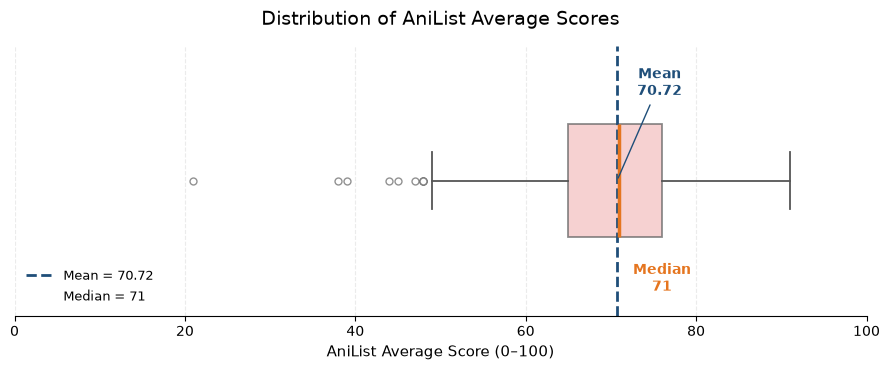

In [27]:
# Distribution of AniList average scores

scores = anime["average_score"].dropna()

# Summary statistics
mean_score   = scores.mean()
median_score = scores.median()
q1           = scores.quantile(0.25)
q3           = scores.quantile(0.75)
n            = scores.count()

fig, ax = plt.subplots(figsize=(9, 3.8))

# Boxplot
ax.boxplot(
    scores,
    orientation="horizontal",
    widths=0.42,
    patch_artist=True,
    
    boxprops=dict(
        facecolor="#F4C2C2",
        edgecolor="#666666",
        linewidth=1.3,
        alpha=0.75
    ),
    
    medianprops=dict(
        color="#E5751F",
        linewidth=2.5
    ),
    
    whiskerprops=dict(
        color="#555555",
        linewidth=1.3
    ),
    
    capprops=dict(
        color="#555555",
        linewidth=1.3
    ),
    
    flierprops=dict(
        marker="o",
        markerfacecolor="white",
        markeredgecolor="#777777",
        markersize=5,
        alpha=0.8
    )
)

# Mean line
ax.axvline(
    mean_score,
    color="#1F4E79",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_score:.2f}"
)

# Median label for legend
ax.axvline(
    median_score,
    color="#E5751F",
    linewidth=2,
    alpha=0,   # invisible extra line only for legend
    label=f"Median = {median_score:.0f}"
)

# Annotate mean
ax.annotate(
    f"Mean\n{mean_score:.2f}",
    xy=(mean_score, 1),
    xytext=(mean_score + 5, 1.30),
    ha="center",
    va="bottom",
    fontsize=10,
    color="#1F4E79",
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="-",
        color="#1F4E79",
        linewidth=1
    )
)

# Annotate median
ax.annotate(
    f"Median\n{median_score:.0f}",
    xy=(median_score, 1),
    xytext=(median_score + 5, 0.70),
    ha="center",
    va="top",
    fontsize=10,
    color="#E5751F",
    fontweight="bold"
)

# Axes
ax.set_xlim(0, 100)
ax.set_xlabel("AniList Average Score (0–100)", fontsize=11)
ax.set_yticks([])

ax.set_title(
    "Distribution of AniList Average Scores",
    fontsize=14,
    pad=15
)

# Light grid only on score axis
ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

# Legend
ax.legend(
    loc="lower left",
    frameon=False,
    fontsize=9.5
)

plt.tight_layout()
plt.show()

In [31]:
def distribution_summary(df, col):
    q1 = df[col].quantile(.25); q3 = df[col].quantile(.75); iqr = q3-q1
    lo = q1-1.5*iqr; hi=q3+1.5*iqr
    outliers = df[(df[col] < lo) | (df[col] > hi)]
    s = pd.DataFrame({
        "Count":[df[col].count()], "Mean":[df[col].mean()], "Median":[df[col].median()],
        "Std Dev":[df[col].std()], "Minimum":[df[col].min()], "Q1":[q1], "Q3":[q3],
        "IQR":[iqr], "Maximum":[df[col].max()], "Lower Bound":[lo], "Upper Bound":[hi],
        "Potential Outliers":[len(outliers)], "Skewness":[df[col].skew()]
    }).T
    s.columns=[f"{col} Summary"]
    return s

display(distribution_summary(anime, "average_score").round(2))

,average_score Summary
Count,1142.00
Mean,70.72
Median,71.00
Std Dev,8.39
Minimum,21.00
Q1,65.00
Q3,76.00
IQR,11.00
Maximum,91.00
Lower Bound,48.50


Average score is slightly right-skewed. The mean is slightly lower than the median. The overall average score is about 70.7, with a median of 71. The middle 50% of titles fall from about 65 to 76. A small number of low-rated observations appear as statistical outliers, but they remain plausible ratings and are retained.

### Distribution of anime popularity

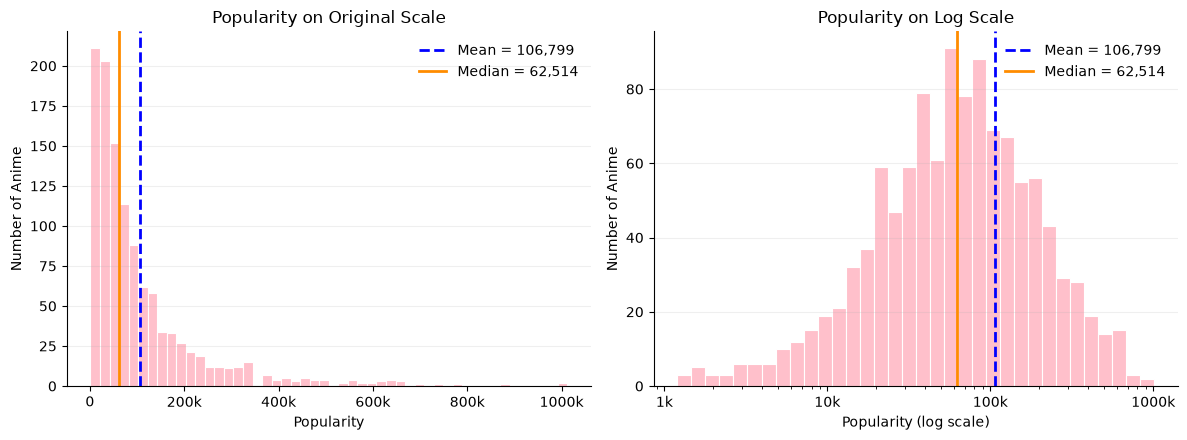

,popularity Summary
Count,1142.00
Mean,106799.13
Median,62514.00
Std Dev,128014.55
Minimum,1202.00
Q1,28893.00
Q3,131534.75
IQR,102641.75
Maximum,1011790.00
Lower Bound,-125069.62


In [40]:
pop = anime["popularity"].dropna()

mean_pop = pop.mean()
median_pop = pop.median()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(
    pop,
    bins=50,
    color="pink",
    edgecolor="white",
    linewidth=0.8
)

axes[0].axvline(
    mean_pop,
    color="blue",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_pop:,.0f}"
)

axes[0].axvline(
    median_pop,
    color="darkorange",
    linestyle="-",
    linewidth=2,
    label=f"Median = {median_pop:,.0f}"
)

axes[0].xaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos: f"{x/1000:.0f}k" if x >= 1000 else f"{x:.0f}"
    )
)

axes[0].set_title("Popularity on Original Scale")
axes[0].set_xlabel("Popularity")
axes[0].set_ylabel("Number of Anime")
axes[0].legend(frameon=False)

positive = pop[pop > 0]

bins = np.logspace(
    np.log10(positive.min()),
    np.log10(positive.max()),
    35
)

axes[1].hist(
    positive,
    bins=bins,
    color="pink",
    edgecolor="white",
    linewidth=0.8
)

axes[1].set_xscale("log")

axes[1].axvline(
    mean_pop,
    color="blue",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_pop:,.0f}"
)

axes[1].axvline(
    median_pop,
    color="darkorange",
    linestyle="-",
    linewidth=2,
    label=f"Median = {median_pop:,.0f}"
)

axes[1].xaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos: f"{x/1000:.0f}k" if x >= 1000 else f"{x:.0f}"
    )
)

axes[1].set_title("Popularity on Log Scale")
axes[1].set_xlabel("Popularity (log scale)")
axes[1].set_ylabel("Number of Anime")
axes[1].legend(frameon=False)

for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

display(distribution_summary(anime, "popularity").round(2))


Popularity is strongly right-skewed. The mean is substantially above the median, and a relatively small number of extremely popular titles extend far beyond most observations. These values appear plausible and should not be deleted simply because they are outliers.

### Distribution of Episode count

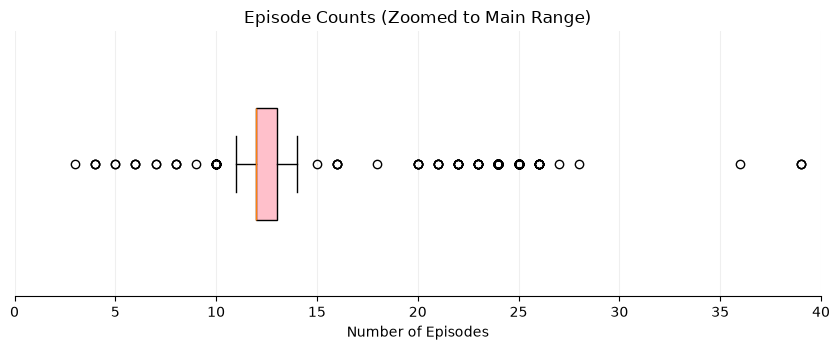

In [63]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))

ax.boxplot(
    ep,
    orientation="horizontal",
    widths=0.42,
    boxprops=dict(facecolor="pink"),
    patch_artist=True
)

ax.set_xlim(0, 40)
ax.set_xlabel("Number of Episodes")
ax.set_title("Episode Counts (Zoomed to Main Range)")
ax.set_yticks([])
ax.grid(axis="x", alpha=0.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

plt.tight_layout()
plt.show()

In [64]:
display(distribution_summary(anime, "episodes").round(2))

,episodes Summary
Count,1142.00
Mean,14.64
Median,12.00
Std Dev,12.01
Minimum,3.00
Q1,12.00
Q3,13.00
IQR,1.00
Maximum,293.00
Lower Bound,10.50


Episode count is right-skewed because most seasonal TV anime have around 12-13 episodes while a smaller number of long-running series contain many more. The maximum of 293 episodes is unusual but plausible.

I used 30 episodes as a practical cutoff for visualizing the main episode-count distribution. Most TV anime in this dataset are concentrated around common seasonal lengths, such as approximately 12-13 episodes or 24-26 episodes. Titles with more than 30 episodes are much less common and create a long right tail that compresses the main part of the distribution when all episode counts are shown on the same scale. The 30-episode cutoff is therefore used only to make the typical episode-count pattern easier to see; titles above 30 episodes are not removed from the dataset or excluded from later analysis.

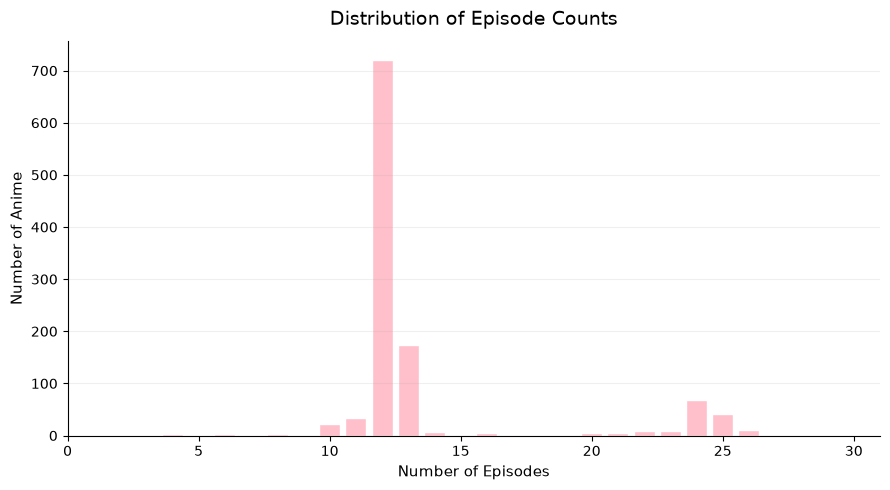

In [51]:
ep = anime["episodes"].dropna()

# Count how many anime have each episode count
episode_counts = ep.value_counts().sort_index()

# Focus on the range where most anime occur
common = episode_counts[episode_counts.index <= 30]

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    common.index,
    common.values,
    width=0.8,
    color="pink",
    edgecolor="white"
)

ax.set_xlabel("Number of Episodes", fontsize=11)
ax.set_ylabel("Number of Anime", fontsize=11)
ax.set_title("Distribution of Episode Counts", fontsize=14, pad=12)

ax.set_xlim(0, 31)
ax.set_xticks(range(0, 31, 5))

ax.grid(axis="y", alpha=0.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [52]:
long_running = anime[anime["episodes"] > 30].sort_values(
    "episodes",
    ascending=False
)

display(
    long_running[
        [
            "title_english",
            "title_romaji",
            "source_group",
            "episodes",
            "average_score"
        ]
    ].head(15)
)

,title_english,title_romaji,source_group,episodes,average_score
159,Boruto: Naruto Next Generations,BORUTO: NARUTO NEXT GENERATIONS,Manga adaptation,293,56.0
161,Black Clover,Black Clover,Manga adaptation,170,79.0
59,Dragon Ball Super,Dragon Ball Super,Manga adaptation,131,73.0
381,Dragon Quest: The Adventure of Dai,Dragon Quest: Dai no Daibouken (2020),Manga adaptation,100,73.0
246,GeGeGe no Kitaro,Gegege no Kitarou (2018),Manga adaptation,97,65.0
236,Captain Tsubasa (2018),Captain Tsubasa (2018),Manga adaptation,52,71.0
407,SHAMAN KING (2021),SHAMAN KING (2021),Manga adaptation,52,64.0
313,Ace of the Diamond act II,Diamond no Ace act II,Manga adaptation,52,82.0
271,CARDFIGHT!! VANGUARD,Cardfight!! Vanguard (2018),Manga adaptation,52,66.0
41,Gintama Season 3,Gintama°,Manga adaptation,51,90.0


In [53]:
n_long = (anime["episodes"] > 30).sum()
pct_long = n_long / len(anime) * 100

print(f"Anime with more than 30 episodes: {n_long}")
print(f"Percentage of dataset: {pct_long:.1f}%")

Anime with more than 30 episodes: 18
Percentage of dataset: 1.6%


### Distribution Source group

,Source Group,Count,Percent
0,Manga adaptation,790,69.2
1,Light novel adaptation,352,30.8


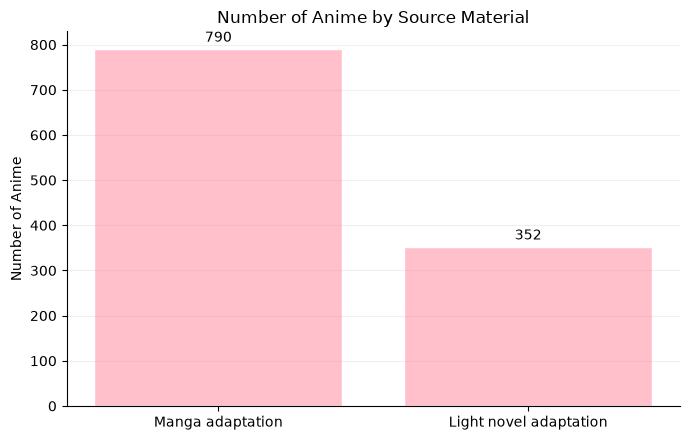

In [67]:
source_counts = anime["source_group"].value_counts().rename_axis("Source Group").reset_index(name="Count")
source_counts["Percent"]=(source_counts["Count"]/len(anime)*100).round(1)
display(source_counts)

source_counts = (
    anime["source_group"]
    .value_counts()
    .rename_axis("Source Group")
    .reset_index(name="Count")
)

fig, ax = plt.subplots(figsize=(7, 4.5))

bars = ax.bar(
    source_counts["Source Group"],
    source_counts["Count"],
    color="pink",
    edgecolor="white"
)

ax.bar_label(
    bars,
    padding=3,
    fontsize=10
)

ax.set_ylabel("Number of Anime")
ax.set_title("Number of Anime by Source Material")

ax.grid(
    axis="y",
    alpha=0.2
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

The groups are unbalanced: approximately 69.2% of observations are manga adaptations and 30.8% are light-novel adaptations. Unequal group sizes are not automatically a problem for the later permutation test, but they should be reported.

### Genre distribution

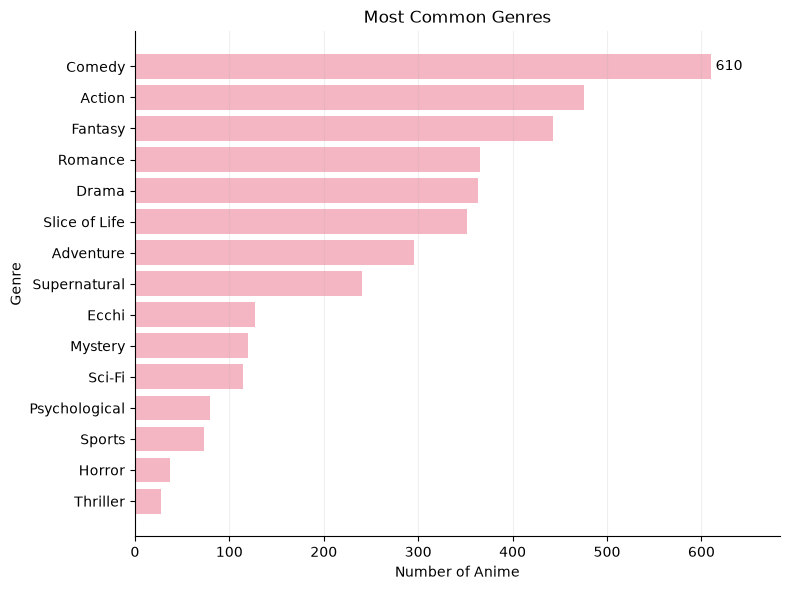

In [74]:
genre_counts=(anime["genres"].str.split("|",regex=False).explode().str.strip().value_counts())
top=genre_counts.head(15).sort_values()

# Label only the highest genre
fig, ax = plt.subplots(figsize=(8, 6))

bars = ax.barh(
    top.index,
    top.values,
    color="#F4B6C2"
)

# Label only the highest genre
max_index = top.values.argmax()

bar = bars[max_index]
value = top.values[max_index]

ax.text(
    bar.get_width() + 5,
    bar.get_y() + bar.get_height() / 2,
    f"{value}",
    va="center",
    fontsize=10
)

ax.set_xlabel("Number of Anime")
ax.set_ylabel("Genre")
ax.set_title("Most Common Genres")

ax.grid(axis="x", alpha=0.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Leave room for the label
ax.set_xlim(0, top.max() * 1.12)

plt.tight_layout()
plt.show()

## 4. Relationships

### Correlations between key numeric variables

In [75]:
relationship_cols=["average_score","popularity","favourites","episodes","duration_min","start_year"]
display(anime[relationship_cols].corr().round(2))

,average_score,popularity,favourites,episodes,duration_min,start_year
average_score,1.00,0.45,0.48,0.05,0.09,0.05
popularity,0.45,1.00,0.88,0.11,0.09,-0.19
favourites,0.48,0.88,1.00,0.13,0.07,-0.10
episodes,0.05,0.11,0.13,1.00,-0.01,-0.10
duration_min,0.09,0.09,0.07,-0.01,1.00,0.02
start_year,0.05,-0.19,-0.10,-0.10,0.02,1.00


`average_score` has a moderate positive association with popularity and favorites, while episode count, duration, and release year have much weaker linear relationships with score. Popularity and favorites are strongly related to each other.

### Average score vs. popularity

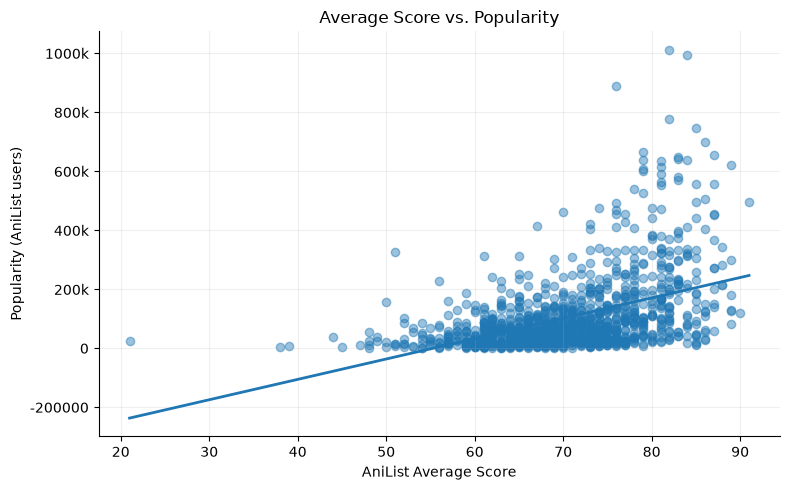

In [76]:
x=anime["average_score"].to_numpy(); y=anime["popularity"].to_numpy()
slope,intercept=np.polyfit(x,y,1); xline=np.linspace(x.min(),x.max(),100)
plt.figure(figsize=(8,5)); plt.scatter(x,y,alpha=0.45); plt.plot(xline,slope*xline+intercept,linewidth=2)
plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda v,pos: f"{v/1000:.0f}k" if v>=1000 else f"{v:.0f}"))
plt.xlabel("AniList Average Score"); plt.ylabel("Popularity (AniList users)"); plt.title("Average Score vs. Popularity")
plt.grid(alpha=0.2); ax=plt.gca(); ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
plt.tight_layout(); plt.show()

### Descriptive comparison of manga vs. light-novel adaptations

In [77]:
group_summary=anime.groupby("source_group")["average_score"].agg(["count","mean","median","std","min","max"]).round(2)
display(group_summary)

,count,mean,median,std,min,max
source_group,,,,,,
Light novel adaptation,352,68.69,69.0,7.65,44.0,89.0
Manga adaptation,790,71.63,72.0,8.55,21.0,91.0


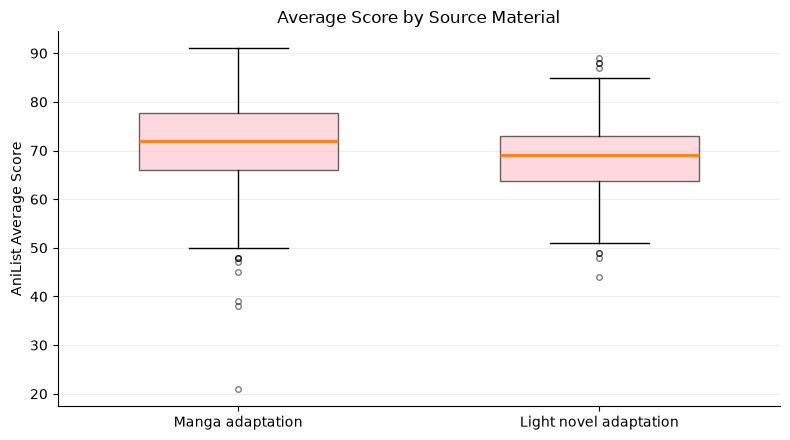

In [80]:
groups=[anime.loc[anime["source_group"]=="Manga adaptation","average_score"], anime.loc[anime["source_group"]=="Light novel adaptation","average_score"]]
fig,ax=plt.subplots(figsize=(8,4.5))
ax.boxplot(groups, tick_labels=["Manga adaptation","Light novel adaptation"], patch_artist=True, widths=0.55, boxprops=dict(alpha=0.6, facecolor="pink"), medianprops=dict(linewidth=2), flierprops=dict(marker="o",markersize=4,alpha=0.5))
ax.set_ylabel("AniList Average Score"); ax.set_title("Average Score by Source Material"); ax.grid(axis="y",alpha=0.2)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False); plt.tight_layout(); plt.show()

Manga adaptations have a higher mean score (71.63) than light-novel adaptations (68.69), an observed difference of about 2.94 points. Their medians are 72 and 69. This is an EDA observation only; the formal permutation test is intentionally reserved for the final analysis.

### Genre composition by source group

In [81]:
genre_rows=anime[["source_group","genres"]].assign(Genre=lambda d:d["genres"].str.split("|",regex=False)).explode("Genre")
genre_rows["Genre"]=genre_rows["Genre"].str.strip()
gs=anime["source_group"].value_counts()
t=genre_rows.groupby(["source_group","Genre"]).size().rename("Count").reset_index()
t["Percent of source group"]=t.apply(lambda r:100*r["Count"]/gs[r["source_group"]],axis=1)
topgenres=genre_rows["Genre"].value_counts().head(10).index
comparison=t[t["Genre"].isin(topgenres)].pivot(index="Genre",columns="source_group",values="Percent of source group").fillna(0).round(1)
display(comparison)

source_group,Light novel adaptation,Manga adaptation
Genre,,
Action,52.6,36.8
Adventure,43.5,18.1
Comedy,40.9,59.0
Drama,23.0,35.7
Ecchi,13.9,9.9
Fantasy,73.9,23.2
Mystery,8.8,11.3
Romance,38.6,29.0
Slice of Life,21.9,34.8


The two groups differ substantially in genre composition. Light-novel adaptations are much more concentrated in Fantasy, Action, and Adventure, while manga adaptations have much larger shares of Comedy, Drama, Slice of Life, and Supernatural titles. This is an important limitation: a later rating difference should not automatically be attributed to source material itself.

### Release-year balance

source_group,Light novel adaptation,Manga adaptation
start_year,,
2015,26,57
2016,16,65
2017,26,64
2018,25,82
2019,21,59
2020,20,52
2021,34,61
2022,30,72
2023,55,90


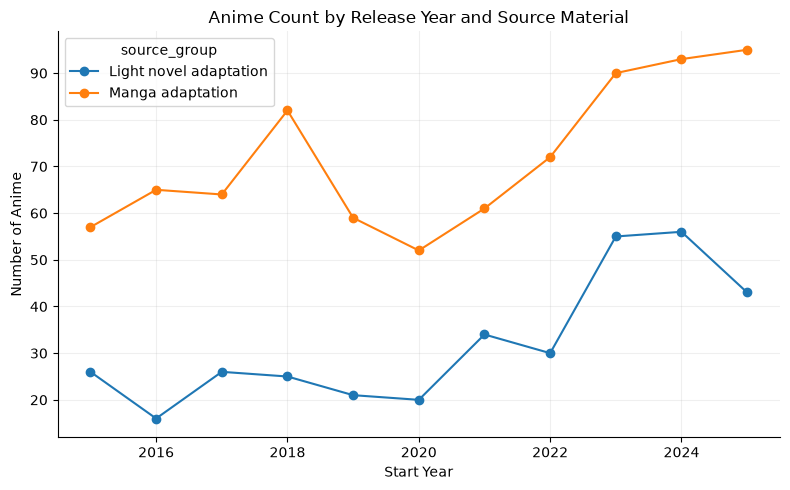

In [82]:
year_source=pd.crosstab(anime["start_year"],anime["source_group"]); display(year_source)
year_source.plot(kind="line",marker="o",figsize=(8,5)); plt.xlabel("Start Year"); plt.ylabel("Number of Anime"); plt.title("Anime Count by Release Year and Source Material"); plt.grid(alpha=0.2)
ax=plt.gca(); ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False); plt.tight_layout(); plt.show()

Both groups appear throughout the 2015-2025 window, although yearly counts differ. Restricting both groups to the same period makes the comparison fairer than combining titles from very different eras.

## 5. Readiness
The dataset is ready for the later Choose Your Own Hypothesis analysis. The planned primary test will use source_group as the grouping variable and `average_score` as the outcome. The test statistic will be the difference in mean rating, **mean(Manga) − mean(Light Novel)**.

For uncertainty, the project can bootstrap the difference in means and the difference in medians. The median supplies the required non-CLT metric.

Important limitations already identified by EDA include unequal group sizes, different genre mixes, self-selected AniList users, separate seasons from the same franchise appearing as separate rows, and the fact that this observational comparison cannot establish causation.